<a href="https://colab.research.google.com/github/pralaynaskar/PyWork/blob/main/Housing_All_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [4]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [5]:
df = pd.read_csv("/content/Housing.csv")

In [6]:
print("Shape: ", df.shape)

Shape:  (545, 13)


In [7]:
print(f"Rows: {df.shape[0]}, Columns {df.shape[1]}\n")

Rows: 545, Columns 13



In [8]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [10]:
print("Missing values per column: ")
print(df.isnull().sum())
print("\nTotal missing: ", df.isnull().sum().sum())

Missing values per column: 
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

Total missing:  0


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0


In [12]:
df.describe(include="object").T

,count,unique,top,freq
mainroad,545,2,yes,468
guestroom,545,2,no,448
basement,545,2,no,354
hotwaterheating,545,2,no,520
airconditioning,545,2,no,373
prefarea,545,2,no,417
furnishingstatus,545,3,semi-furnished,227


In [13]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  0


In [14]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
  print(f"{col}: {df[col].unique()}")

mainroad: ['yes' 'no']
guestroom: ['no' 'yes']
basement: ['no' 'yes']
hotwaterheating: ['no' 'yes']
airconditioning: ['yes' 'no']
prefarea: ['yes' 'no']
furnishingstatus: ['furnished' 'semi-furnished' 'unfurnished']


In [15]:
target = 'price'
X = df.drop(columns=target)
y = df[target]

In [16]:
print("Features shape: ", X.shape)
print("Target shape: ", y.shape)

Features shape:  (545, 12)
Target shape:  (545,)


In [17]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
bin_cols = [c for c in cat_cols if df[c].nunique() == 2]
multi_cat_cols = [c for c in cat_cols if df[c].nunique() > 2]

In [18]:
print("Number columns: ", num_cols)
print("Binary columns: ", bin_cols)
print("Multi-categorical columns: ", multi_cat_cols)

Number columns:  ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Binary columns:  ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
Multi-categorical columns:  ['furnishingstatus']


In [19]:
X_encoded = X.copy()
for col in bin_cols:
  X_encoded[col] = X_encoded[col].map({'yes': 1, 'no': 0})

In [20]:
X_encoded = pd.get_dummies(X_encoded, columns=multi_cat_cols, drop_first=True, dtype=int)

In [22]:
print("Encoded features shape: ", X_encoded.shape)
X_encoded.head()

Encoded features shape:  (545, 13)


,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,7420,4,1,2,1,1,1,0,1,2,0,0,0


In [23]:
print("Remaining object columns: ", X_encoded.select_dtypes(include='object').columns.tolist())
print("Any NaN?", X_encoded.isnull().sum().sum())

Remaining object columns:  []
Any NaN? 0


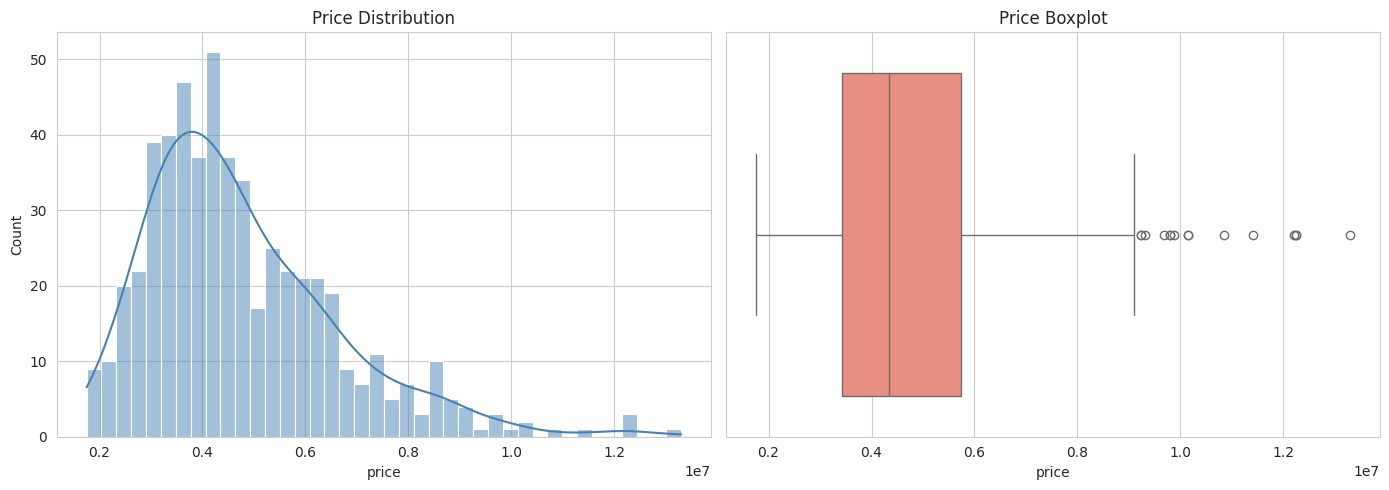

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(y, bins=40, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title("Price Distribution")

sns.boxplot(x=y, ax=axes[1], color='salmon')
axes[1].set_title("Price Boxplot")

plt.tight_layout()
plt.show()

In [28]:
print(f"Skewness: {y.skew()}")

Skewness: 1.2122388370279802


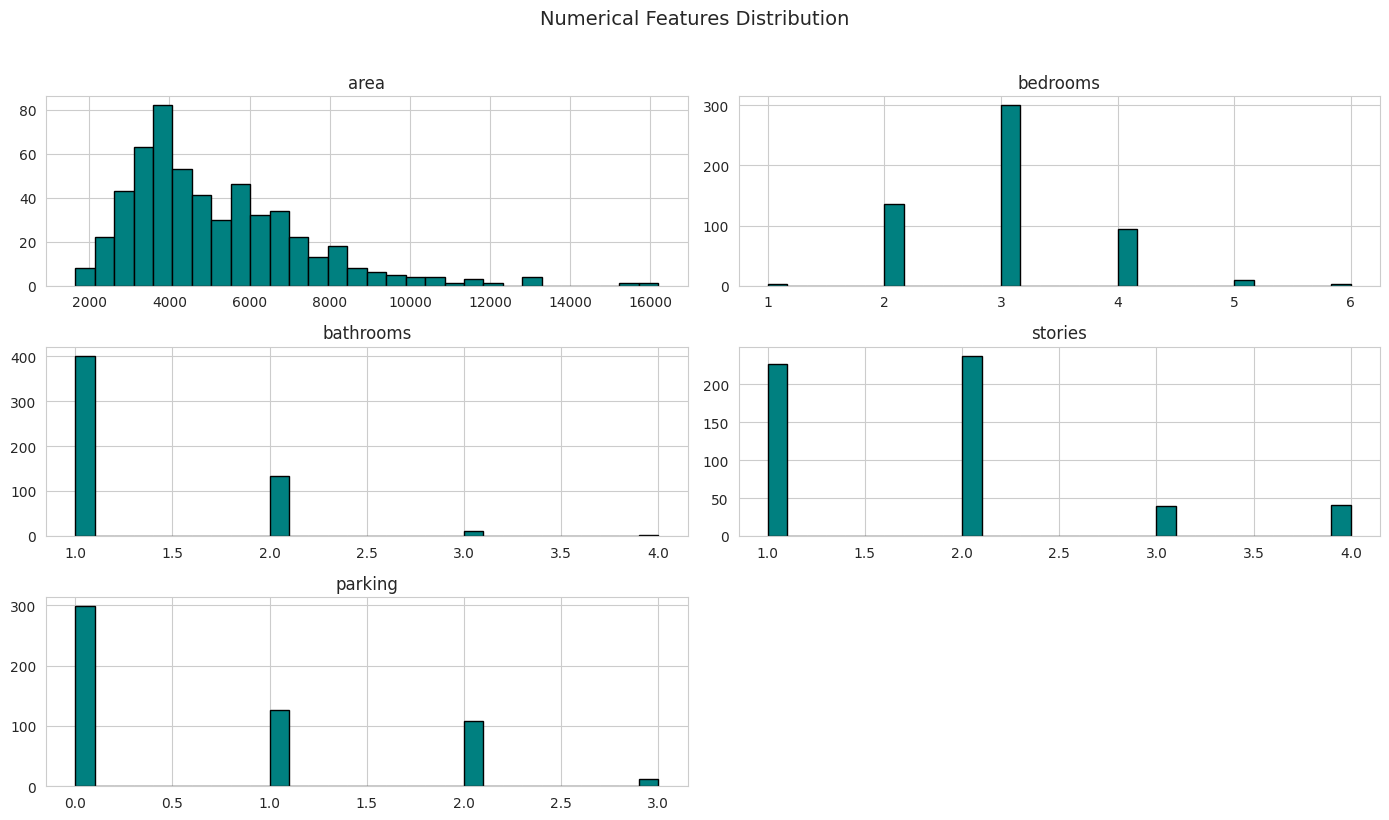

In [30]:
X_encoded[num_cols].hist(bins=30, figsize=(14, 8), color='teal', edgecolor='black')

plt.suptitle("Numerical Features Distribution", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

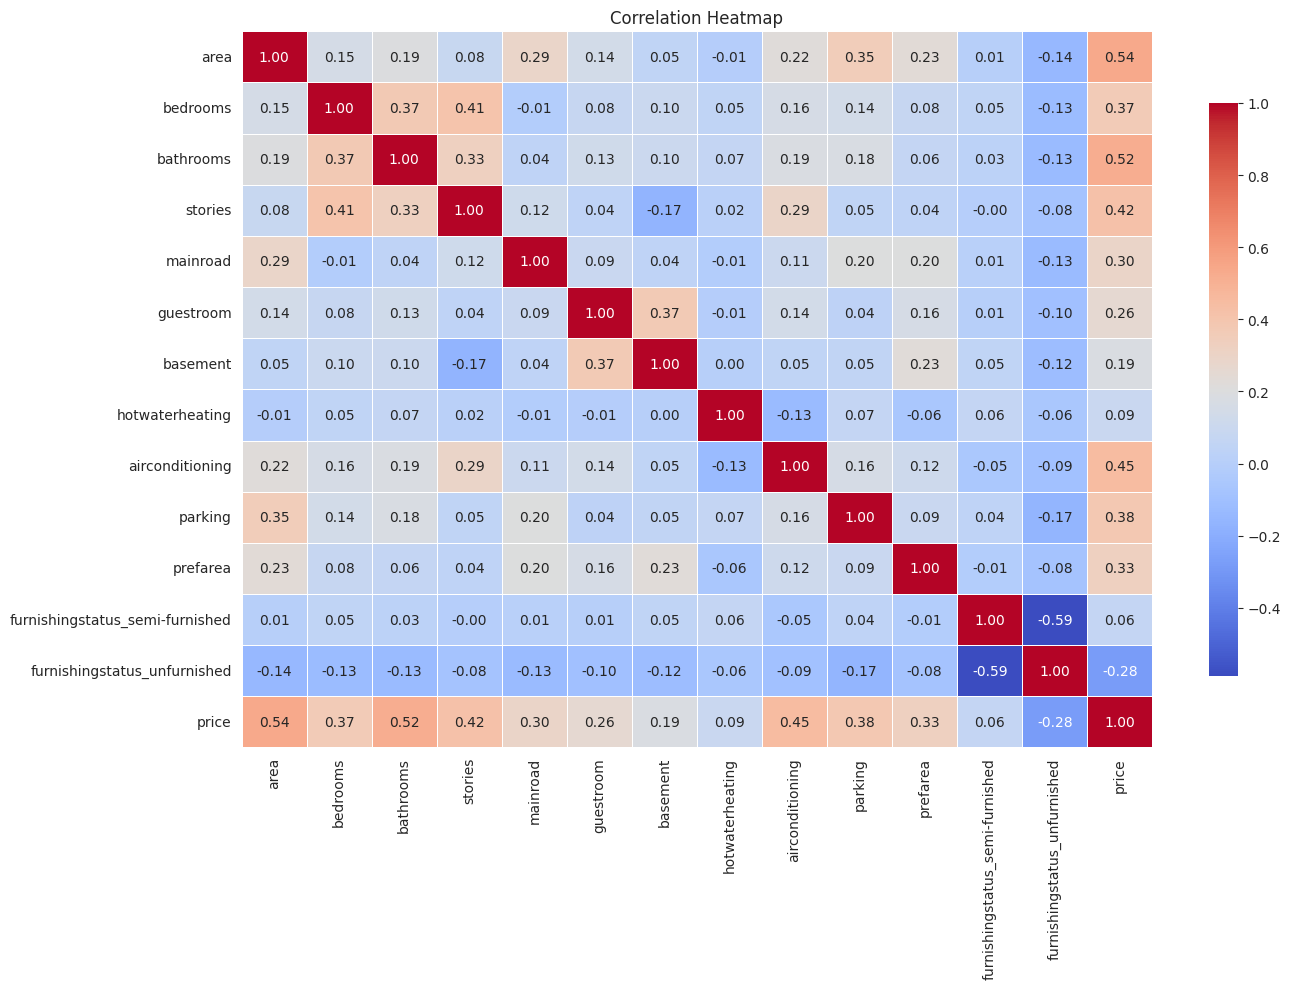

In [31]:
corr_df = pd.concat([X_encoded, y], axis=1)

plt.figure(figsize=(14, 10))

sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, cbar_kws={'shrink': 0.8})

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [32]:
corr_with_target = corr_df.corr()[target].drop(target).sort_values(ascending=False)

print("Correlation with PRICE:\n")
print(corr_with_target)

Correlation with PRICE:

area                               0.535997
bathrooms                          0.517545
airconditioning                    0.452954
stories                            0.420712
parking                            0.384394
bedrooms                           0.366494
prefarea                           0.329777
mainroad                           0.296898
guestroom                          0.255517
basement                           0.187057
hotwaterheating                    0.093073
furnishingstatus_semi-furnished    0.063656
furnishingstatus_unfurnished      -0.280587
Name: price, dtype: float64


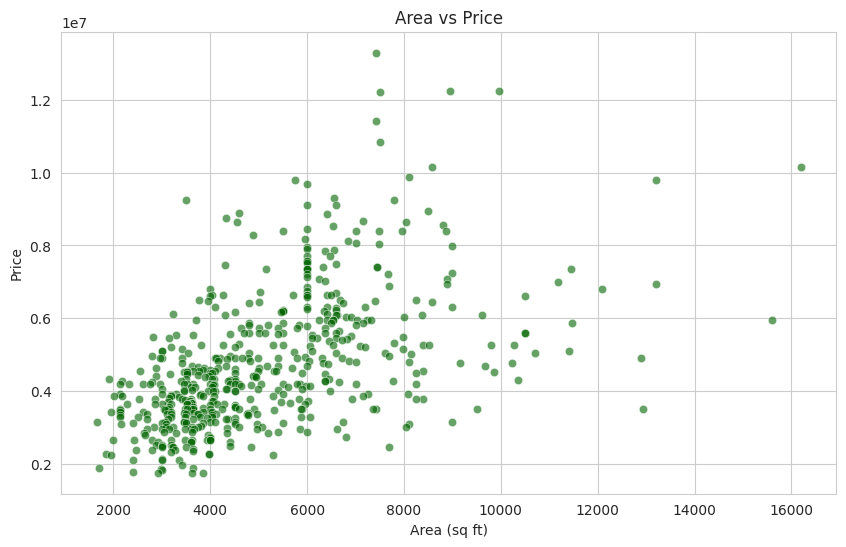

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x=X_encoded['area'], y=y, alpha=0.6, color='darkgreen')

plt.title("Area vs Price")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price")
plt.show()

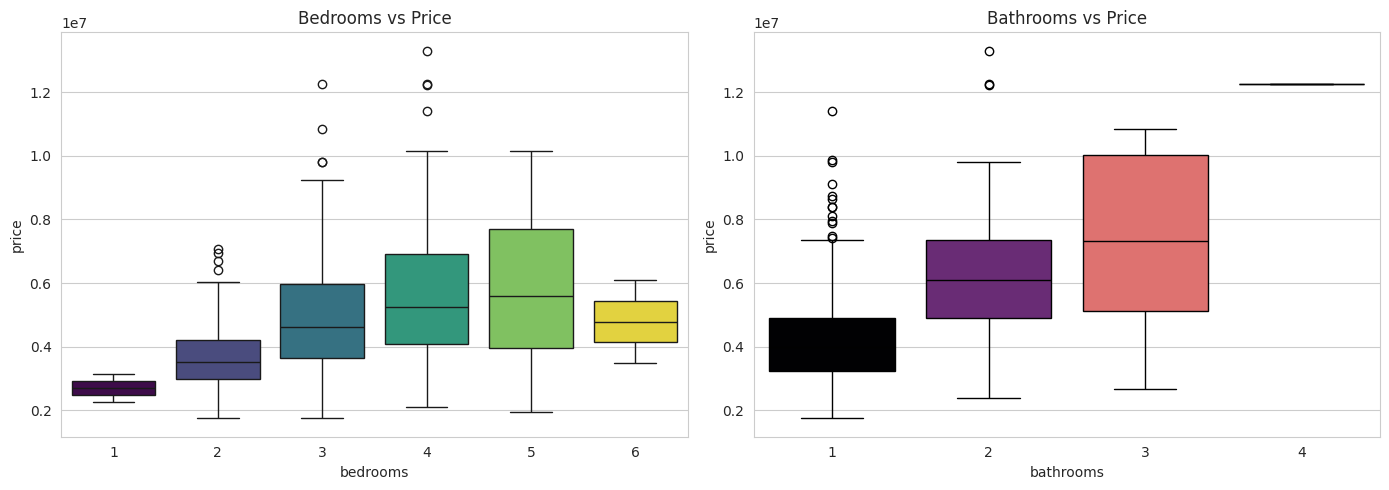

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x=X['bedrooms'], y=y, hue=X['bedrooms'], palette='viridis', legend=False, ax=axes[0])
axes[0].set_title("Bedrooms vs Price")

sns.boxplot(x=X['bathrooms'], y=y, hue=X['bathrooms'], palette='magma', legend=False, ax=axes[1])
axes[1].set_title("Bathrooms vs Price")

plt.tight_layout()
plt.show()

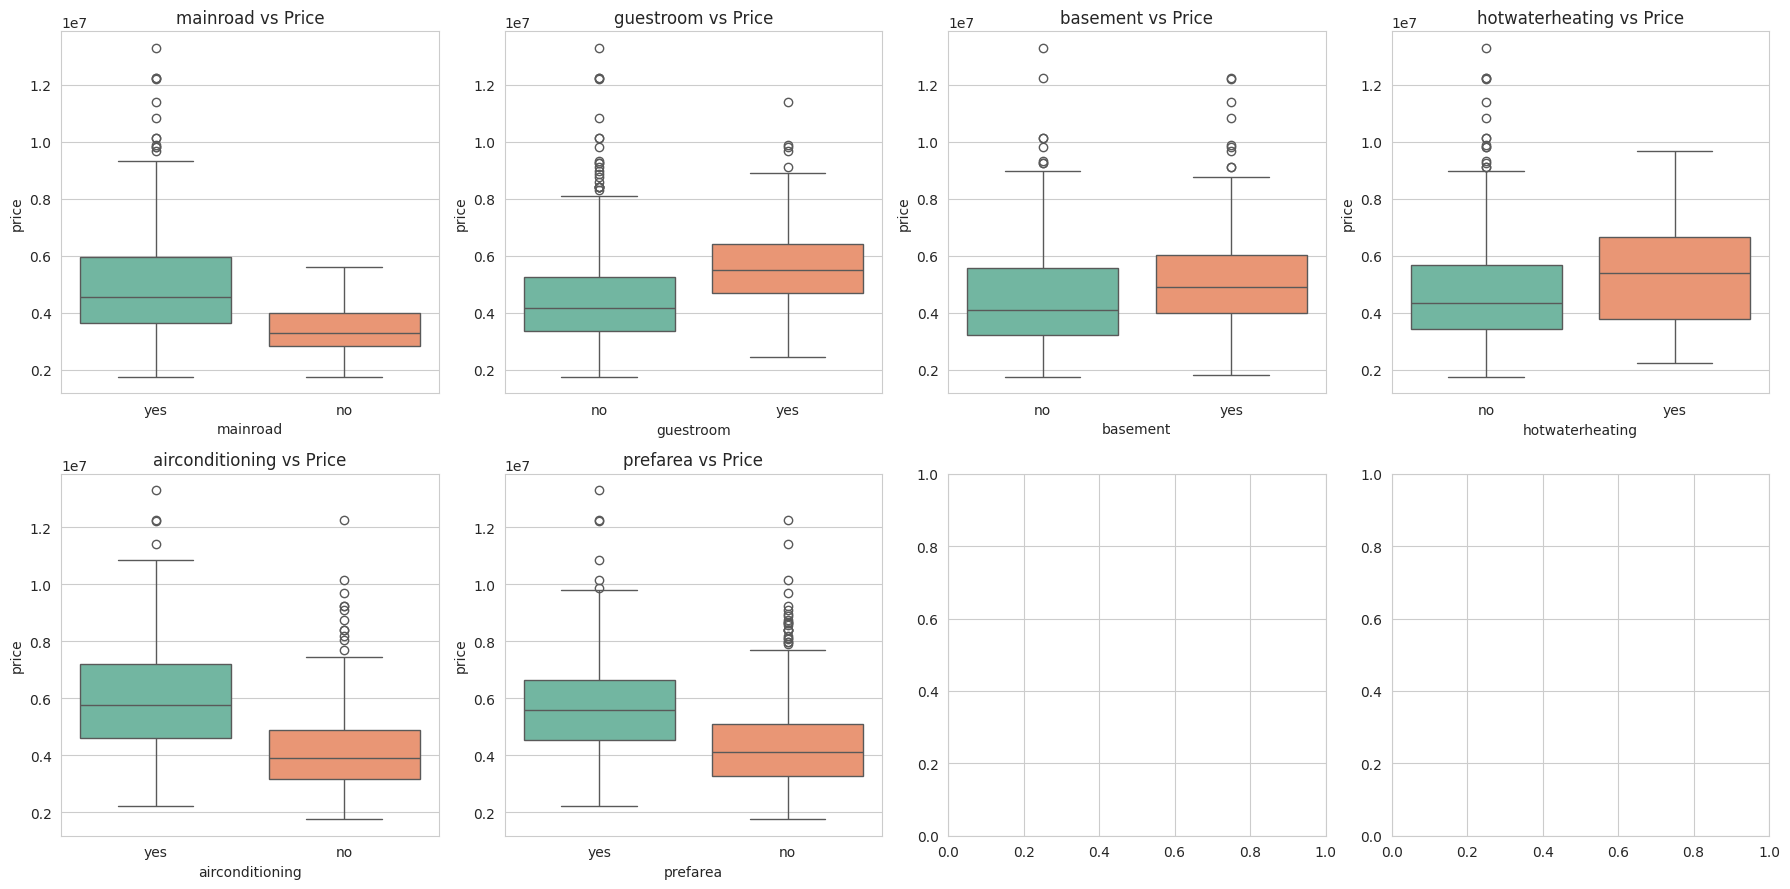

In [37]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(bin_cols):
    sns.boxplot(x=X[col], y=y, hue=X[col], palette='Set2', legend=False, ax=axes[i])
    axes[i].set_title(f"{col} vs Price")

plt.tight_layout()
plt.show()

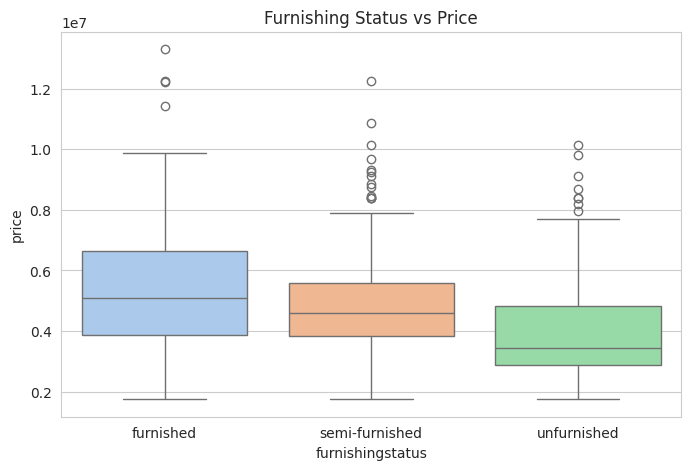

In [38]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=X['furnishingstatus'], y=y, hue=X['furnishingstatus'], palette='pastel', legend=False)

plt.title("Furnishing Status vs Price")
plt.show()

In [39]:
Q1, Q3 = X_encoded['area'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
outliers = X_encoded[(X_encoded['area'] < lower) | (X_encoded['area'] > upper)]

print(f"Area outliers: {len(outliers)} rows ({len(outliers)/len(X_encoded)*100:.1f}%)")
print(f"Bounds: [{lower:.0f}, {upper:.0f}]")

Area outliers: 12 rows (2.2%)
Bounds: [-540, 10500]


In [40]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (436, 13) | Test: (109, 13)


In [42]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0, random_state=RANDOM_STATE))
    ]),
    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(alpha=0.1, random_state=RANDOM_STATE, max_iter=10000))
    ]),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, random_state=RANDOM_STATE
    ),
}

print("Models defined:", list(models.keys()))

Models defined: ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Random Forest', 'Gradient Boosting']


In [43]:
trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    trained_models[name] = model
    predictions[name] = preds
    print(f"Trained: {name}")

Trained: Linear Regression
Trained: Ridge Regression
Trained: Lasso Regression
Trained: Random Forest
Trained: Gradient Boosting


In [44]:
cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train,
                             cv=5, scoring='r2', n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:20s} CV R² = {scores.mean():.4f} ± {scores.std():.4f}")

Linear Regression    CV R² = 0.6470 ± 0.0367
Ridge Regression     CV R² = 0.6472 ± 0.0365
Lasso Regression     CV R² = 0.6470 ± 0.0367
Random Forest        CV R² = 0.5905 ± 0.0373
Gradient Boosting    CV R² = 0.5769 ± 0.0223


In [45]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}

rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5, estimator=RandomForestRegressor(n_jobs=-1, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [100, 200, 300]},
             scoring='r2', verbose=1)

In [46]:
print("\nBest params:", rf_grid.best_params_)
print(f"Best CV R²: {rf_grid.best_score_:.4f}")

best_rf = rf_grid.best_estimator_


Best params: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
Best CV R²: 0.6172


In [47]:
def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return {"Model": name, "MAE": mae, "RMSE": rmse,
            "R²": r2, "MAPE (%)": mape}

In [48]:
results = [evaluate(name, y_test, predictions[name]) for name in models]

In [49]:
best_rf.fit(X_train, y_train)
tuned_preds = best_rf.predict(X_test)
results.append(evaluate("Random Forest (Tuned)", y_test, tuned_preds))

results_df = pd.DataFrame(results).sort_values("R²", ascending=False)
results_df.reset_index(drop=True, inplace=True)
print("\n=== MODEL COMPARISON (Test Set) ===")
print(results_df.to_string(index=False))


=== MODEL COMPARISON (Test Set) ===
                Model          MAE         RMSE       R²  MAPE (%)
    Gradient Boosting 9.452530e+05 1.287074e+06 0.672265 20.433978
    Linear Regression 9.700434e+05 1.324507e+06 0.652924 21.035523
     Lasso Regression 9.700434e+05 1.324507e+06 0.652924 21.035524
     Ridge Regression 9.698579e+05 1.324703e+06 0.652821 21.034451
        Random Forest 1.014947e+06 1.399769e+06 0.612360 21.730176
Random Forest (Tuned) 1.056576e+06 1.450848e+06 0.583553 22.431692


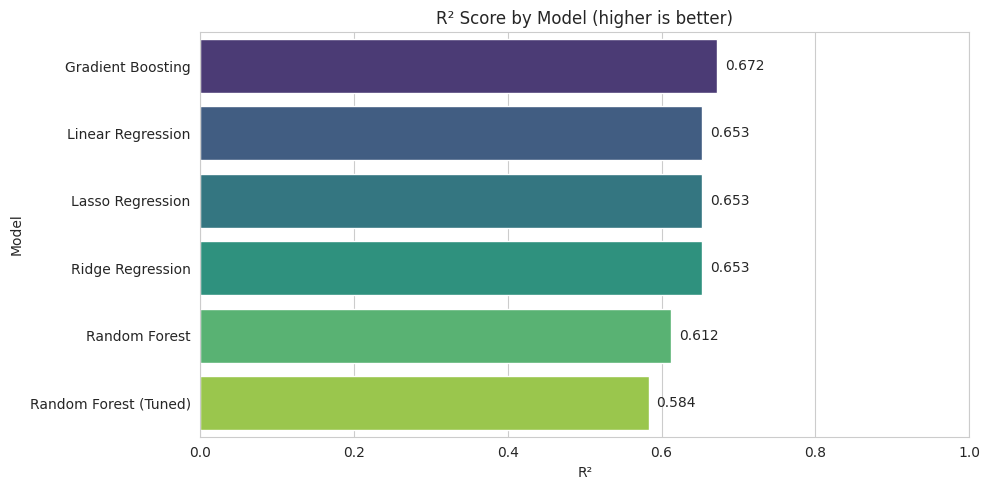

In [51]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="R²", y="Model", hue="Model", palette="viridis", legend=False)
plt.title("R² Score by Model (higher is better)")
plt.xlim(0, 1)

for i, v in enumerate(results_df["R²"]):
    plt.text(v + 0.01, i, f"{v:.3f}", va='center')

plt.tight_layout()
plt.show()

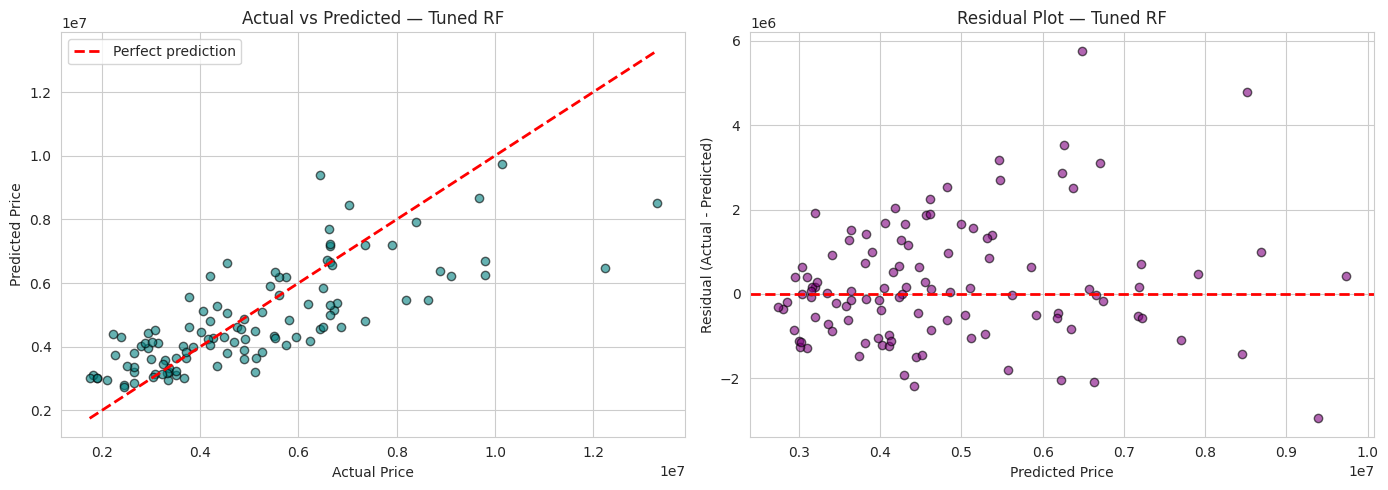

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, tuned_preds, alpha=0.6, color='teal', edgecolor='k')
lims = [min(y_test.min(), tuned_preds.min()), max(y_test.max(), tuned_preds.max())]
axes[0].plot(lims, lims, 'r--', lw=2, label="Perfect prediction")
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
axes[0].set_title("Actual vs Predicted — Tuned RF")
axes[0].legend()

residuals = y_test - tuned_preds
axes[1].scatter(tuned_preds, residuals, alpha=0.6, color='purple', edgecolor='k')
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot — Tuned RF")

plt.tight_layout()
plt.show()

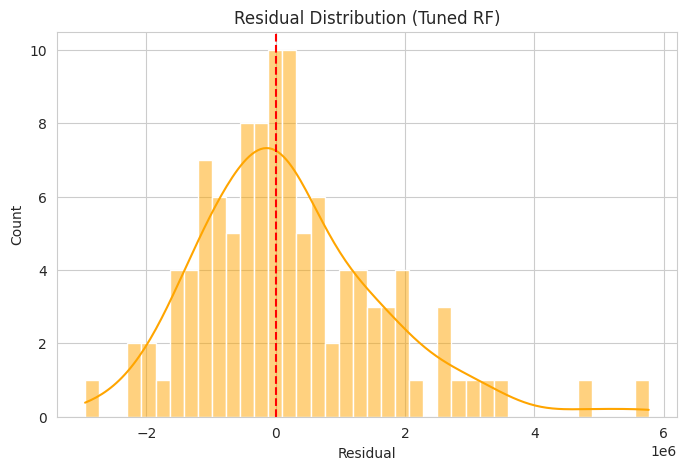

Mean residual: 224,983
Std  residual: 1,439,918


In [54]:
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True, color='orange')
plt.axvline(0, color='red', linestyle='--')
plt.title("Residual Distribution (Tuned RF)")
plt.xlabel("Residual")
plt.show()
print(f"Mean residual: {residuals.mean():,.0f}")
print(f"Std  residual: {residuals.std():,.0f}")

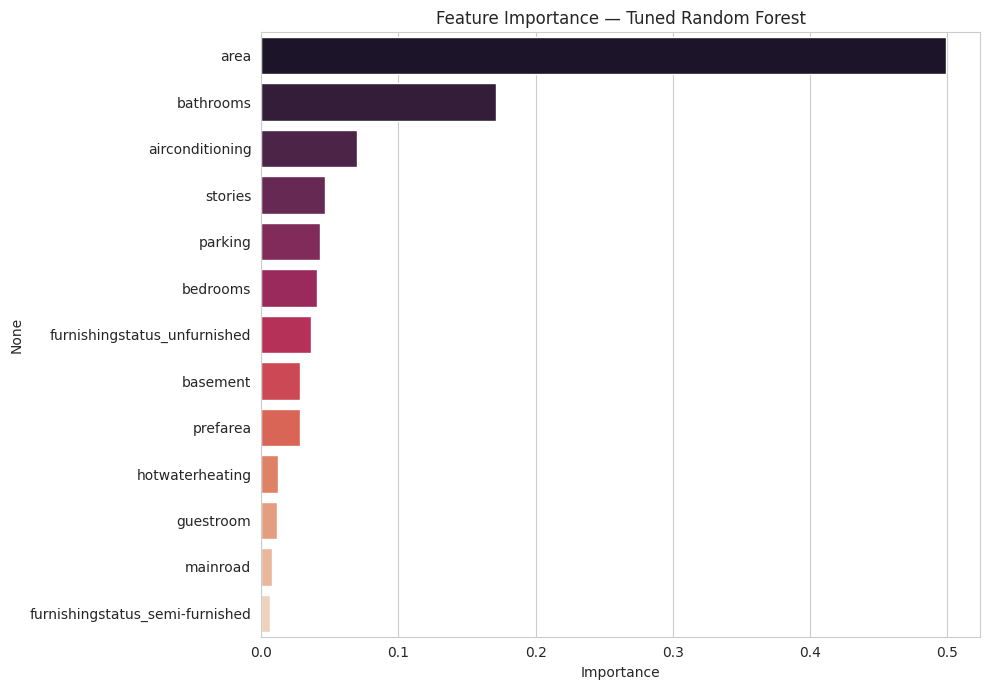

area                            0.498883
bathrooms                       0.171013
airconditioning                 0.069527
stories                         0.046555
parking                         0.043189
bedrooms                        0.040347
furnishingstatus_unfurnished    0.036083
basement                        0.028201
prefarea                        0.028151
hotwaterheating                 0.012032
dtype: float64


In [56]:
importances = pd.Series(
    best_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette='rocket', legend=False)
plt.title("Feature Importance — Tuned Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print(importances.head(10))

In [57]:
best_row = results_df.iloc[0]
print("=" * 55)
print("           FINAL MODEL SUMMARY")
print("=" * 55)
print(f"Best Model    : {best_row['Model']}")
print(f"MAE           : {best_row['MAE']:,.0f}")
print(f"RMSE          : {best_row['RMSE']:,.0f}")
print(f"R²            : {best_row['R²']:.4f}")
print(f"MAPE          : {best_row['MAPE (%)']:.2f}%")
print("=" * 55)

           FINAL MODEL SUMMARY
Best Model    : Gradient Boosting
MAE           : 945,253
RMSE          : 1,287,074
R²            : 0.6723
MAPE          : 20.43%


In [58]:
import joblib
joblib.dump(best_rf, "housing_price_model.pkl")
print("✅ Model saved as 'housing_price_model.pkl'")

✅ Model saved as 'housing_price_model.pkl'


In [59]:
new_house = pd.DataFrame([{
    'area': 6000, 'bedrooms': 3, 'bathrooms': 2, 'stories': 2,
    'mainroad': 1, 'guestroom': 0, 'basement': 0, 'hotwaterheating': 0,
    'airconditioning': 1, 'parking': 1, 'prefarea': 1,
    'furnishingstatus_semi-furnished': 1,
    'furnishingstatus_unfurnished': 0
}])

predicted = best_rf.predict(new_house)[0]
print(f"Predicted price for sample house: ₹{predicted:,.0f}")

Predicted price for sample house: ₹8,048,578
